In [1]:
# Connect Google Drive to this Colab notebook so the CSV can be read from Drive.

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# List the files and folders in MyDrive to check where the dataset is stored.

import os

print(os.listdir('/content/drive/MyDrive'))

['marksheet_merged.pdf', 'repo (2).png', 'repo (1).png', 'repo.png', 'Colab Notebooks', 'IMG20260115104339_01.jpg.adding', 'IMG20260115110729.jpg.adding', 'IMG20260115104357_01.jpg.adding', 'IMG20260115105336_01.jpg.adding', 'IMG20260115105319_01.jpg.adding', 'IMG20260115111636_01.jpg.adding', 'IMG20260115112333_01.jpg', 'IMG20260115101535.jpg', 'IMG20260115112747_01.jpg', 'IMG20260115104536_01.jpg', 'Assignment_1.ipynb', 'Screenshot_2026-04-08-09-38-17-65_40deb401b9ffe8e1df2f1cc5ba480b12.jpg', 'WhatsApp Image 2026-04-08 at 11.36.31.jpeg', 'Experiment4_Dhruvi_Srivastava.pdf', 'Experiment6_Dhruvi_Srivastava.pdf', 'Experiment5_Dhruvi-Srivastava.pdf', 'Experiment7_Dhruvi_Srivastava.pdf', 'Screenshot 2026-04-28 232813.png', 'ML_weekly_projects.gsheet', 'Untitled spreadsheet.gsheet', 'NexusCRM_Demo.mp4', 'Crime_Atlas', 'Breast_Cancer_detection', 'WhatsApp Video 2026-06-26 at 21.18.40.mp4', 'NA Student List .gsheet', 'RescueNet.pptx', 'Short Attendance (NA).gsheet', '450018567381017_dhruvi s

In [32]:
# Import pandas, set the CSV path, load the dataset, and preview its rows and dimensions.

import pandas as pd
import numpy as np
file_path = '/content/drive/MyDrive/DS/data_application_energy.csv'

df = pd.read_csv(file_path)

print(df.head())
print(df.shape)

                  date  Appliances  lights     T1       RH_1    T2       RH_2  \
0  2016-01-11 17:00:00          60      30  19.89  47.596667  19.2  44.790000   
1  2016-01-11 17:10:00          60      30  19.89  46.693333  19.2  44.722500   
2  2016-01-11 17:20:00          50      30  19.89  46.300000  19.2  44.626667   
3  2016-01-11 17:30:00          50      40  19.89  46.066667  19.2  44.590000   
4  2016-01-11 17:40:00          60      40  19.89  46.333333  19.2  44.530000   

      T3       RH_3         T4  ...         T9   RH_9     T_out  Press_mm_hg  \
0  19.79  44.730000  19.000000  ...  17.033333  45.53  6.600000        733.5   
1  19.79  44.790000  19.000000  ...  17.066667  45.56  6.483333        733.6   
2  19.79  44.933333  18.926667  ...  17.000000  45.50  6.366667        733.7   
3  19.79  45.000000  18.890000  ...  17.000000  45.40  6.250000        733.8   
4  19.79  45.000000  18.890000  ...  17.000000  45.40  6.133333        733.9   

   RH_out  Windspeed  Visibility

In [4]:
# Confirm that the dataset loaded and display its shape and column names.

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
print("Column names:", df.columns.tolist())

Dataset loaded successfully!
Rows and columns: (19735, 29)
Column names: ['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2']


In [5]:
# Inspect column data types, count missing values, check duplicate rows, and view summary statistics.

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nColumn data types:")
print(df.dtypes)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  object 
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-nu

In [6]:
# Convert the date column from text to datetime so time-based information can be extracted.

df['date'] = pd.to_datetime(df['date'], errors='raise')

print(df['date'].dtype)
print(df['date'].head())

datetime64[ns]
0   2016-01-11 17:00:00
1   2016-01-11 17:10:00
2   2016-01-11 17:20:00
3   2016-01-11 17:30:00
4   2016-01-11 17:40:00
Name: date, dtype: datetime64[ns]


In [7]:
# Check whether rv1 and rv2 contain exactly the same values before removing them.

print("Are rv1 and rv2 identical?",
      df['rv1'].equals(df['rv2']))

Are rv1 and rv2 identical? True


In [8]:
# Remove the two redundant auxiliary columns after confirming that they are identical.

df = df.drop(columns=['rv1', 'rv2'])

print("Updated shape:", df.shape)

Updated shape: (19735, 27)


In [9]:
# Extract hour, day of the week, month, and a weekend indicator from the timestamp.

df['hour'] = df['date'].dt.hour
df['day_of_week'] = df['date'].dt.dayofweek
df['month'] = df['date'].dt.month
df['is_weekend'] = (df['date'].dt.dayofweek >= 5).astype(int)

display(df[['date', 'hour', 'day_of_week',
            'month', 'is_weekend']].head())

,date,hour,day_of_week,month,is_weekend
0,2016-01-11 17:00:00,17,0,1,0
1,2016-01-11 17:10:00,17,0,1,0
2,2016-01-11 17:20:00,17,0,1,0
3,2016-01-11 17:30:00,17,0,1,0
4,2016-01-11 17:40:00,17,0,1,0


In [10]:
# Save the processed dataset as a new CSV file in Google Drive, leaving the original file unchanged.

output_path = '/content/drive/MyDrive/preprocessed_energy.csv'

df.to_csv(output_path, index=False)

print("Preprocessed dataset saved to Google Drive!")
print("Final shape:", df.shape)

Preprocessed dataset saved to Google Drive!
Final shape: (19735, 31)


In [11]:
# Recheck the processed dataset's shape, missing values, duplicate rows, data types, and sample records.

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (19735, 31)

Missing values:
0

Duplicate rows:
0

Data types:
date           datetime64[ns]
Appliances              int64
lights                  int64
T1                    float64
RH_1                  float64
T2                    float64
RH_2                  float64
T3                    float64
RH_3                  float64
T4                    float64
RH_4                  float64
T5                    float64
RH_5                  float64
T6                    float64
RH_6                  float64
T7                    float64
RH_7                  float64
T8                    float64
RH_8                  float64
T9                    float64
RH_9                  float64
T_out                 float64
Press_mm_hg           float64
RH_out                float64
Windspeed             float64
Visibility            float64
Tdewpoint             float64
hour                    int32
day_of_week             int32
month                   int32
is_weekend            

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,hour,day_of_week,month,is_weekend
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,6.600000,733.5,92.0,7.000000,63.000000,5.3,17,0,1,0
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,6.483333,733.6,92.0,6.666667,59.166667,5.2,17,0,1,0
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,6.366667,733.7,92.0,6.333333,55.333333,5.1,17,0,1,0
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,6.250000,733.8,92.0,6.000000,51.500000,5.0,17,0,1,0
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,6.133333,733.9,92.0,5.666667,47.666667,4.9,17,0,1,0


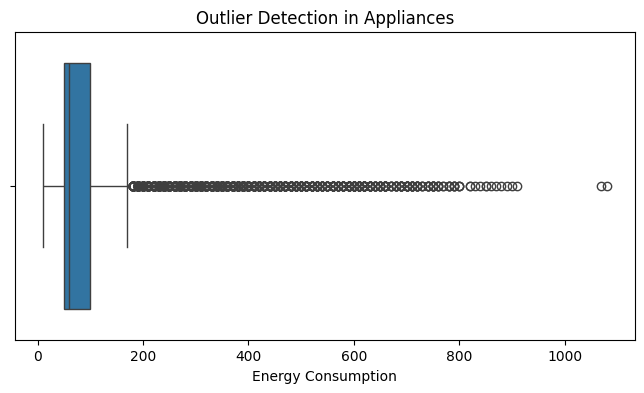

In [12]:
# Draw a box plot to visually inspect potential outliers in appliance energy consumption.

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
sns.boxplot(x=df['Appliances'])

plt.title('Outlier Detection in Appliances')
plt.xlabel('Energy Consumption')
plt.show()

In [13]:
# Use the IQR rule to flag unusually low or high Appliances values; this identifies candidates, not necessarily errors.

Q1 = df['Appliances'].quantile(0.25)
Q3 = df['Appliances'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df['Appliances'] < lower_limit) |
    (df['Appliances'] > upper_limit)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of potential outliers:", len(outliers))

Q1: 50.0
Q3: 100.0
IQR: 50.0
Lower limit: -25.0
Upper limit: 175.0
Number of potential outliers: 2138


In [14]:
# Apply the IQR rule to each numerical column and summarize the number and percentage of potential outliers.

numeric_cols = df.select_dtypes(include='number').columns

outlier_summary = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_summary.append({
        'Column': col,
        'Outlier Count': count,
        'Outlier Percentage': round(count / len(df) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)

display(
    outlier_df.sort_values(
        by='Outlier Percentage',
        ascending=False
    )
)

,Column,Outlier Count,Outlier Percentage
1,lights,4483,22.72
24,Visibility,2522,12.78
0,Appliances,2138,10.83
11,RH_5,1330,6.74
4,T2,546,2.77
12,T6,515,2.61
2,T1,515,2.61
20,T_out,436,2.21
22,RH_out,239,1.21
5,RH_2,235,1.19


In [15]:
# Review summary statistics and the ten highest appliance readings to judge whether extreme values may be valid.

print("Appliances statistics:")
print(df["Appliances"].describe())

print("\nHighest energy readings:")
display(
    df.nlargest(10, "Appliances")[["date", "Appliances", "lights"]]
)

print("\nLight usage distribution:")
print(df["lights"].value_counts().sort_index().tail(10))

Appliances statistics:
count    19735.000000
mean        97.694958
std        102.524891
min         10.000000
25%         50.000000
50%         60.000000
75%        100.000000
max       1080.000000
Name: Appliances, dtype: float64

Highest energy readings:


,date,Appliances,lights
731,2016-01-16 18:50:00,1080,30
1451,2016-01-21 18:50:00,1070,30
432,2016-01-14 17:00:00,910,0
12088,2016-04-04 15:40:00,900,0
1452,2016-01-21 19:00:00,890,20
10668,2016-03-25 19:00:00,880,10
14693,2016-04-22 17:50:00,870,0
9031,2016-03-14 10:10:00,860,0
1821,2016-01-24 08:30:00,850,20
19582,2016-05-26 16:40:00,850,0



Light usage distribution:
lights
0     15252
10     2212
20     1624
30      559
40       77
50        9
60        1
70        1
Name: count, dtype: int64


In [16]:
# Save the final processed dataframe to Google Drive again after the inspection steps.

df.to_csv(
    '/content/drive/MyDrive/preprocessed_energy.csv',
    index=False
)

print("Final preprocessed dataset saved successfully!")

Final preprocessed dataset saved successfully!


Summary Statistics for Appliances


,Appliances
count,19735.000000
mean,97.694958
std,102.524891
min,10.000000
25%,50.000000
50%,60.000000
75%,100.000000
max,1080.000000


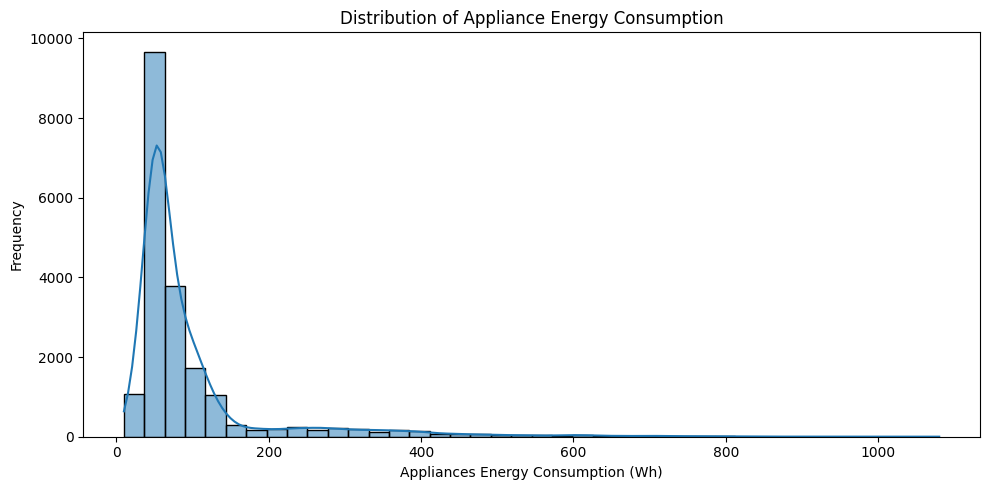

In [19]:

# EDA 1: Distribution of appliance energy consumption

print("Summary Statistics for Appliances")
display(df['Appliances'].describe())

plt.figure(figsize=(10, 5))
sns.histplot(data=df, x='Appliances', bins=40, kde=True)

plt.title('Distribution of Appliance Energy Consumption')
plt.xlabel('Appliances Energy Consumption (Wh)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


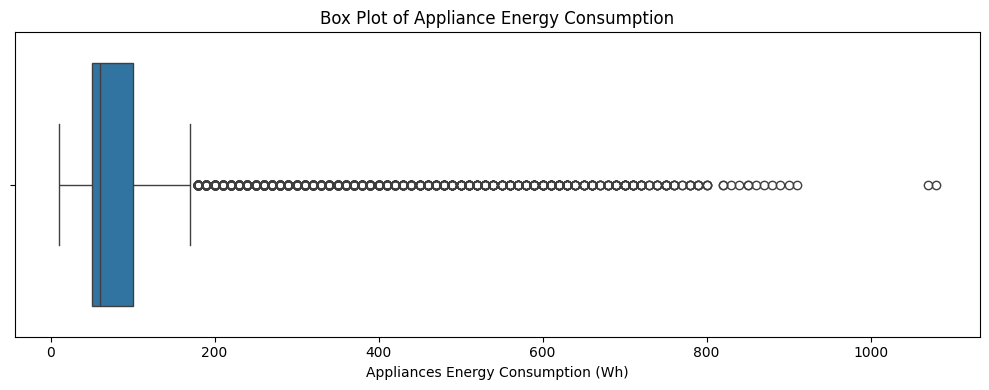

In [20]:

plt.figure(figsize=(10, 4))

sns.boxplot(x=df['Appliances'])

plt.title('Box Plot of Appliance Energy Consumption')
plt.xlabel('Appliances Energy Consumption (Wh)')

plt.tight_layout()
plt.show()


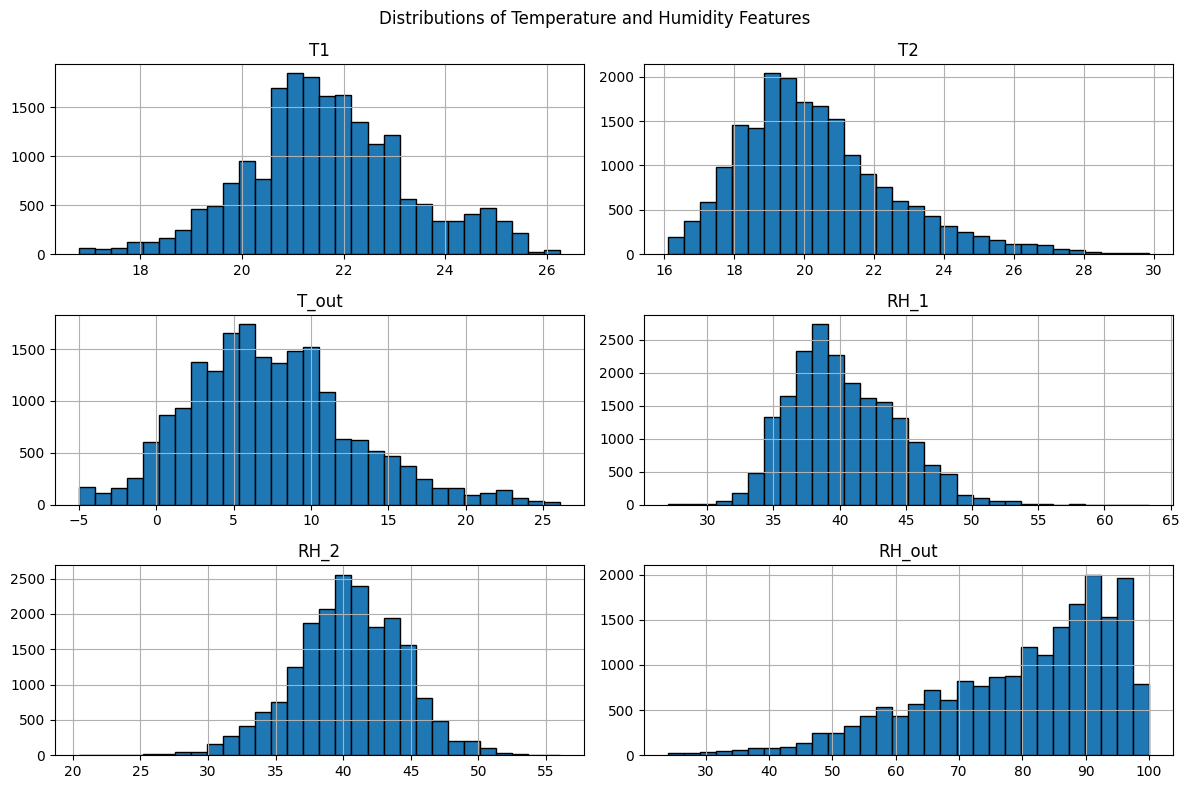

In [21]:

# EDA 3: Distribution of temperature and humidity features

selected_features = ['T1', 'T2', 'T_out', 'RH_1', 'RH_2', 'RH_out']

df[selected_features].hist(
    figsize=(12, 8),
    bins=30,
    edgecolor='black'
)

plt.suptitle('Distributions of Temperature and Humidity Features')
plt.tight_layout()
plt.show()


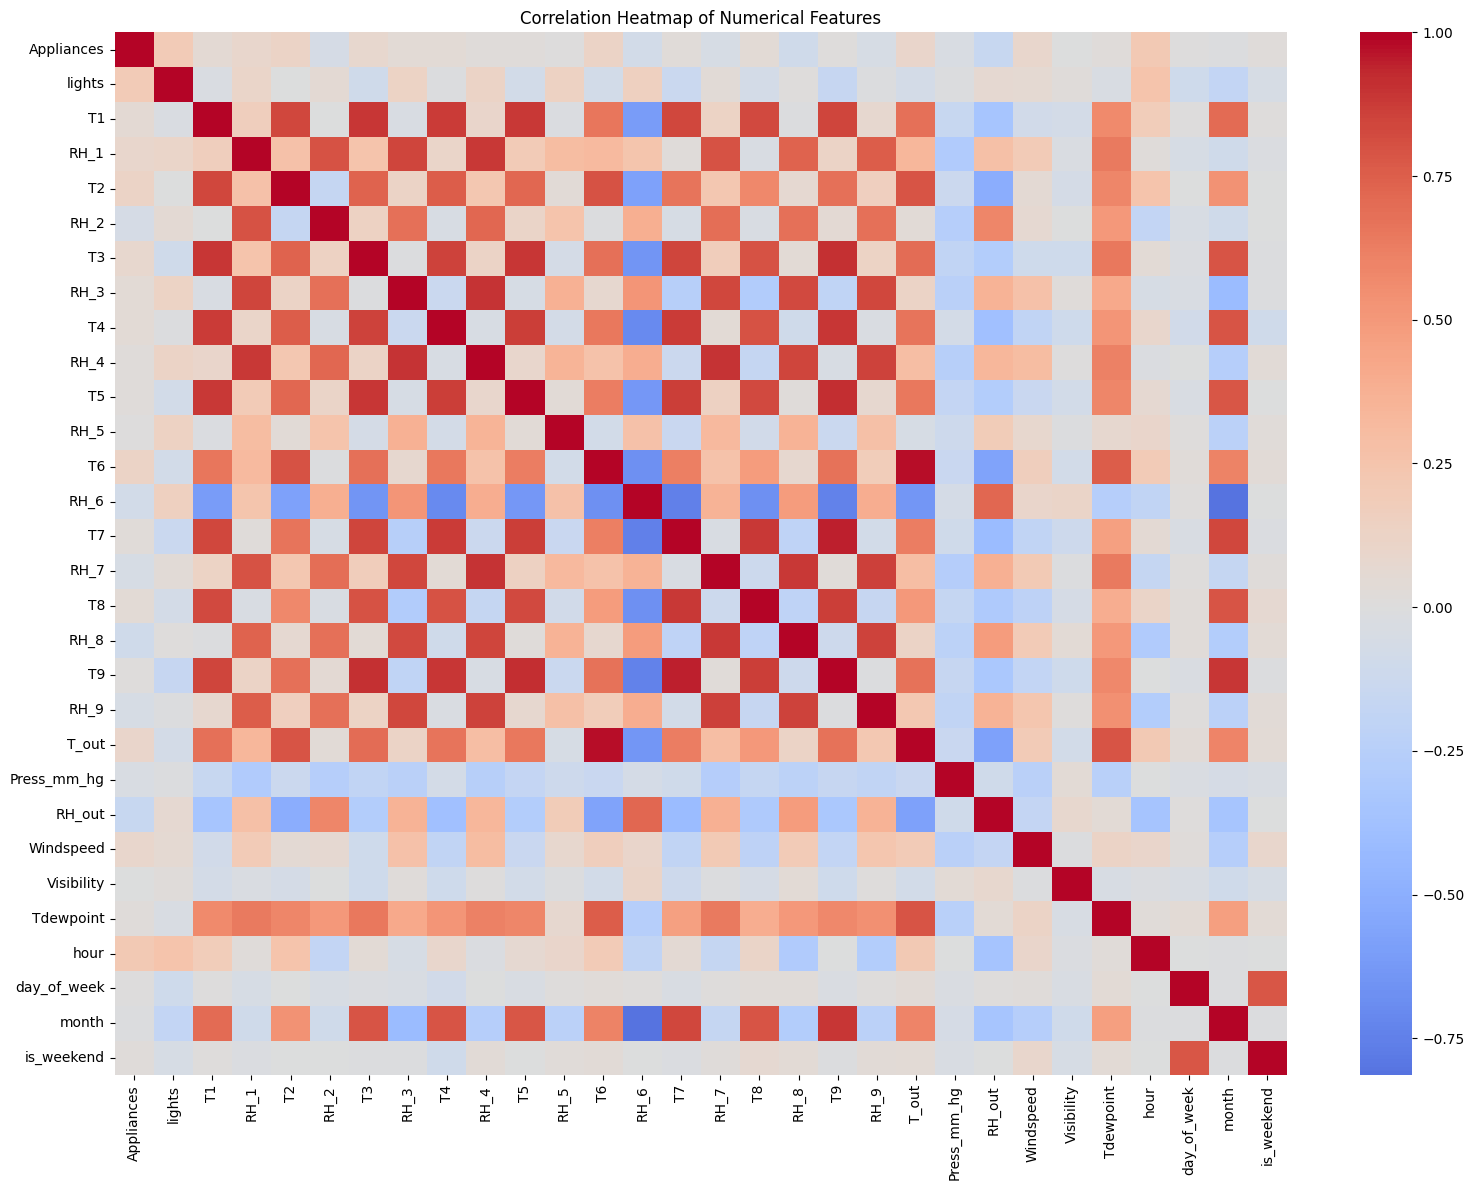

Correlation with Appliances:


,Appliances
hour,0.216792
lights,0.197278
RH_out,-0.152282
T2,0.120073
T6,0.117638
T_out,0.099155
RH_8,-0.094039
Windspeed,0.087122
RH_1,0.086031
T3,0.085060


In [22]:

# EDA 4: Correlation analysis

numeric_df = df.select_dtypes(include='number')
correlation = numeric_df.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0,
    annot=False
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

# Display the features most correlated with Appliances
print("Correlation with Appliances:")
display(
    correlation['Appliances']
    .drop('Appliances')
    .sort_values(key=abs, ascending=False)
    .head(10)
)


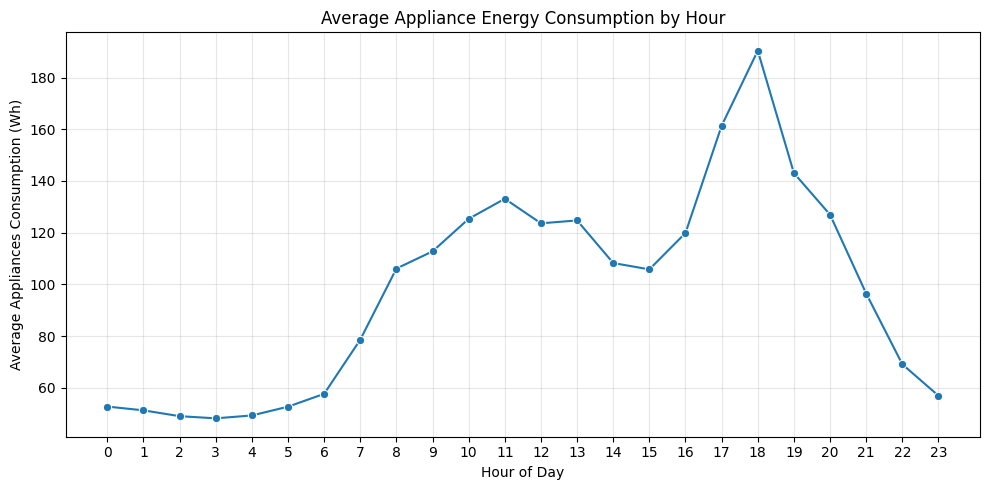

,hour,Appliances
0,0,52.785888
1,1,51.326034
2,2,49.075426
3,3,48.236010
4,4,49.355231
5,5,52.737226
6,6,57.712895
7,7,78.649635
8,8,106.143552
9,9,112.785888


In [23]:

# EDA 5: Average appliance consumption by hour

hourly_consumption = (
    df.groupby('hour')['Appliances']
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=hourly_consumption,
    x='hour',
    y='Appliances',
    marker='o'
)

plt.title('Average Appliance Energy Consumption by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Appliances Consumption (Wh)')
plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

display(hourly_consumption)



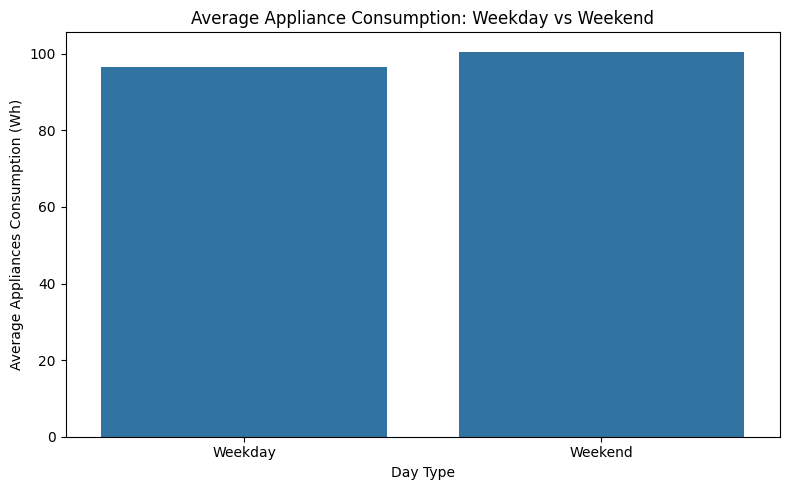

Average consumption by day type:


,mean,median,count
day_type,,,
Weekday,96.59,60.0,14263
Weekend,100.58,70.0,5472


In [24]:

# EDA 6: Compare weekday and weekend consumption

df['day_type'] = df['is_weekend'].map({
    0: 'Weekday',
    1: 'Weekend'
})

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x='day_type',
    y='Appliances',
    estimator='mean',
    errorbar=None
)

plt.title('Average Appliance Consumption: Weekday vs Weekend')
plt.xlabel('Day Type')
plt.ylabel('Average Appliances Consumption (Wh)')

plt.tight_layout()
plt.show()

print("Average consumption by day type:")
display(
    df.groupby('day_type')['Appliances']
    .agg(['mean', 'median', 'count'])
    .round(2)
)


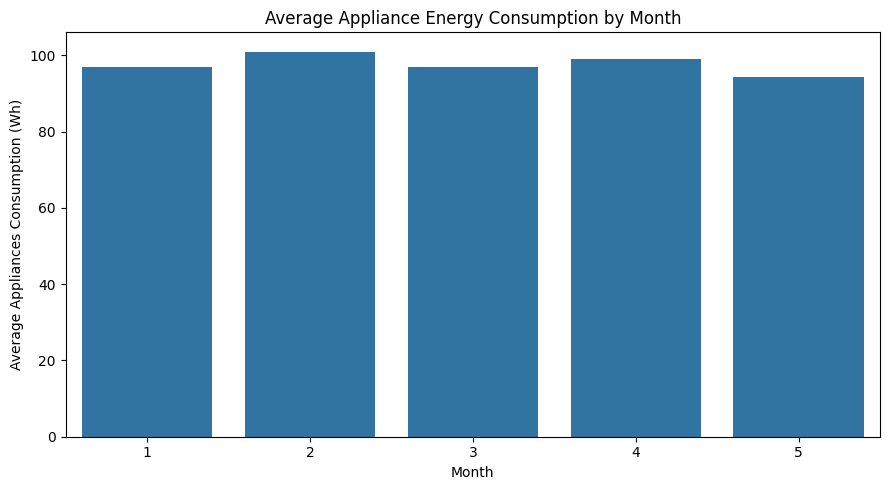

,month,Appliances
0,1,97.03
1,2,100.95
2,3,96.95
3,4,98.89
4,5,94.20


In [25]:

# EDA 7: Average appliance consumption by month

monthly_consumption = (
    df.groupby('month')['Appliances']
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=monthly_consumption,
    x='month',
    y='Appliances',
    errorbar=None
)

plt.title('Average Appliance Energy Consumption by Month')
plt.xlabel('Month')
plt.ylabel('Average Appliances Consumption (Wh)')
plt.tight_layout()
plt.show()

display(monthly_consumption.round(2))


### Key EDA Findings

- Appliance energy consumption is right-skewed: most readings are relatively low, with a smaller number of high-consumption readings.
- Average appliance consumption is lowest around 3 AM (approximately 48.2 Wh) and highest around 6 PM (approximately 190.4 Wh).
- Mean consumption is approximately 96.6 Wh on weekdays and 100.6 Wh on weekends.
- Monthly averages range from approximately 94.2 Wh in May to 101.0 Wh in February. The dataset covers only part of the year, so these values do not establish a full annual seasonal pattern.
- Correlation indicates association, not causation; the observed relationships should not be interpreted as proof that a feature causes appliance consumption.


In [26]:

# Review the outlier summary created earlier

display(
    outlier_df.sort_values(
        by='Outlier Count',
        ascending=False
    ).head(10)
)


,Column,Outlier Count,Outlier Percentage
1,lights,4483,22.72
24,Visibility,2522,12.78
0,Appliances,2138,10.83
11,RH_5,1330,6.74
4,T2,546,2.77
12,T6,515,2.61
2,T1,515,2.61
20,T_out,436,2.21
22,RH_out,239,1.21
5,RH_2,235,1.19


In [27]:

# Inspect distributions and unique values before outlier treatment

for col in ['lights', 'Visibility', 'RH_5', 'T1', 'T2', 'T6', 'T_out', 'RH_out']:
    print(f"\n--- {col} ---")
    print(df[col].describe())
    print("Unique values:", df[col].nunique())
    print("Lowest values:", sorted(df[col].dropna().unique())[:10])
    print("Highest values:", sorted(df[col].dropna().unique())[-10:])



--- lights ---
count    19735.000000
mean         3.801875
std          7.935988
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max         70.000000
Name: lights, dtype: float64
Unique values: 8
Lowest values: [np.int64(0), np.int64(10), np.int64(20), np.int64(30), np.int64(40), np.int64(50), np.int64(60), np.int64(70)]
Highest values: [np.int64(0), np.int64(10), np.int64(20), np.int64(30), np.int64(40), np.int64(50), np.int64(60), np.int64(70)]

--- Visibility ---
count    19735.000000
mean        38.330834
std         11.794719
min          1.000000
25%         29.000000
50%         40.000000
75%         40.000000
max         66.000000
Name: Visibility, dtype: float64
Unique values: 413
Lowest values: [np.float64(1.0), np.float64(1.16666666666667), np.float64(1.33333333333333), np.float64(1.5), np.float64(1.66666666666667), np.float64(1.8333333333333297), np.float64(2.0), np.float64(2.16666666666667), np.float64(2.3333333333333295), np.float

### Outlier Analysis and Treatment Decision

The IQR method identified potential outliers in several numerical features, including 2,138 `Appliances` observations above the upper IQR limit of 175 Wh. These are statistical flags, not proof of invalid measurements. The inspected values appeared plausible for household energy data, and no confirmed data-entry errors were identified. The original observations are therefore retained in this notebook rather than deleting potentially valid energy-use events. This means outlier detection has been completed, but row-level outlier removal has not been performed. If the assessment strictly requires removal, confirm the instructor's preferred method before changing the data.


In [28]:

# Sort observations chronologically
df = df.sort_values('date').reset_index(drop=True)

# Remove the temporary EDA-only column
df_model = df.drop(columns=['day_type'], errors='ignore').copy()

# Separate features and target
X = df_model.drop(columns=['Appliances', 'date'])
y = df_model['Appliances']

# Use the first 80% for training and the last 20% for testing
split_index = int(len(df_model) * 0.8)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining period:")
print(df_model['date'].iloc[0], "to", df_model['date'].iloc[split_index - 1])

print("\nTesting period:")
print(df_model['date'].iloc[split_index], "to", df_model['date'].iloc[-1])


Training features: (15788, 29)
Testing features: (3947, 29)
Training target: (15788,)
Testing target: (3947,)

Training period:
2016-01-11 17:00:00 to 2016-04-30 08:10:00

Testing period:
2016-04-30 08:20:00 to 2016-05-27 18:00:00


In [29]:

from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit only on training data, then transform both sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

# Check the training data after scaling
X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

print("\nTraining feature means (first 10):")
display(X_train_scaled_df.mean().head(10).round(4))

print("\nTraining feature standard deviations (first 10):")
display(X_train_scaled_df.std(ddof=0).head(10).round(4))


Scaled training shape: (15788, 29)
Scaled testing shape: (3947, 29)

Training feature means (first 10):


,0
lights,0.0
T1,0.0
RH_1,0.0
T2,0.0
RH_2,0.0
T3,0.0
RH_3,0.0
T4,-0.0
RH_4,0.0
T5,0.0



Training feature standard deviations (first 10):


,0
lights,1.0
T1,1.0
RH_1,1.0
T2,1.0
RH_2,1.0
T3,1.0
RH_3,1.0
T4,1.0
RH_4,1.0
T5,1.0


In [30]:

# Check whether any non-numeric features remain

print("Feature data types:")
display(X.dtypes.value_counts())

non_numeric_columns = X.select_dtypes(
    exclude=['number']
).columns.tolist()

print("Non-numeric columns:", non_numeric_columns)

print("\nBinary feature check:")
print(X['is_weekend'].value_counts().sort_index())


Feature data types:


,count
float64,24
int32,3
int64,2


Non-numeric columns: []

Binary feature check:
is_weekend
0    14263
1     5472
Name: count, dtype: int64


In [33]:
print("Training rows:", len(X_train_scaled))
print("Testing rows:", len(X_test_scaled))

print("Missing values in training features:", np.isnan(X_train_scaled).sum())
print("Missing values in testing features:", np.isnan(X_test_scaled).sum())

print("Missing values in training target:", y_train.isna().sum())
print("Missing values in testing target:", y_test.isna().sum())

print(
    "Training and testing overlap:",
    len(set(X_train.index).intersection(set(X_test.index)))
)

Training rows: 15788
Testing rows: 3947
Missing values in training features: 0
Missing values in testing features: 0
Missing values in training target: 0
Missing values in testing target: 0
Training and testing overlap: 0


## Conclusion

This notebook examined household appliance energy consumption and environmental measurements. The dataset was checked for missing values and duplicate rows, the date column was converted to datetime, redundant `rv1` and `rv2` columns were removed after confirming they were identical, and time-based features were created. EDA showed a right-skewed appliance-consumption distribution, higher average consumption around 6 PM, and modest differences between weekday and weekend averages. Potential outliers were detected using the IQR method and inspected; because no invalid observations were confirmed, the original readings were retained. The modelling features were split chronologically into training and testing sets, and `StandardScaler` was fitted on the training set only before being applied to the test set. Final validation confirmed 15,788 training rows, 3,947 testing rows, no missing values in the scaled features or target sets, and no index overlap.

**Limitation:** The dataset covers January to May 2016, so the analysis cannot describe full-year seasonality. This notebook prepares and validates the data for later modelling; it does not train or evaluate a predictive model.
